## XGBoost Feature Ablation

Similar to the NN ablation notebook, this experiment examines several design choices, but with our XGBoost model instead of a standard MLP neural network. As this is a baseline model with different architecture, the features we examine will vary from our NN slightly, as follows:
- Feature engineering on log-moneyness, as before
- Standardization of input space and output space $X, y,$ and log-transform of our target (hence predicting $\log{\frac{C}{K}}$ instead of $\frac{C}{K}.$
- No model architecture; the model architecture as-is only acts as a baseline.
- No hybrid loss, as our base model already uses standard MSE.

### Control Model

We begin with a baseline model incorporating all features above. 

The baseline model is trained on the following dataset:
- 100,000 training samples, 10,000 eval samples.
- $\log{\frac{S}{K}} \in [-2, 2]$
- $T \in [0.1, 2],$ with a log-normal distribution.
- $\sigma \in (0.1, 0.5)$
- $r$ set constant at $r = 0.02.$

For implementation details and hyperparameters, reference `constants.py`.
 

In [ ]:
import sys

sys.path.append("..")

from src.constants import NN_MODEL_PATH
from data.bs_dataset_generator import DataConfig, generate_bundle
from src.eval.validate import compute_metrics, plot_validation_results, preprocess_test_data, print_metrics_report
from src.training.train_xgboost import predict, train
import pandas as pd

In [2]:
# training is done on default hyperparams.
cfg = DataConfig()
dataset_bundle = generate_bundle(cfg)

X_train, y_train = dataset_bundle.train.X, dataset_bundle.train.y_call
X_val, y_val = dataset_bundle.val.X, dataset_bundle.val.y_call
    
xgb_model, norm_params = train(
    X_train, y_train, X_val, y_val
)

[0]	validation_0-rmse:0.95012
[50]	validation_0-rmse:0.16082
[100]	validation_0-rmse:0.07467
[150]	validation_0-rmse:0.06115
[200]	validation_0-rmse:0.05378
[250]	validation_0-rmse:0.05080
[300]	validation_0-rmse:0.04781
[350]	validation_0-rmse:0.04556
[400]	validation_0-rmse:0.04308
[450]	validation_0-rmse:0.04125
[499]	validation_0-rmse:0.03969


[0]	validation_0-rmse:0.95012
[50]	validation_0-rmse:0.16082
[100]	validation_0-rmse:0.07467
[150]	validation_0-rmse:0.06115
[200]	validation_0-rmse:0.05378
[250]	validation_0-rmse:0.05080
[300]	validation_0-rmse:0.04781
[350]	validation_0-rmse:0.04556
[400]	validation_0-rmse:0.04308
[450]	validation_0-rmse:0.04125
[499]	validation_0-rmse:0.03969


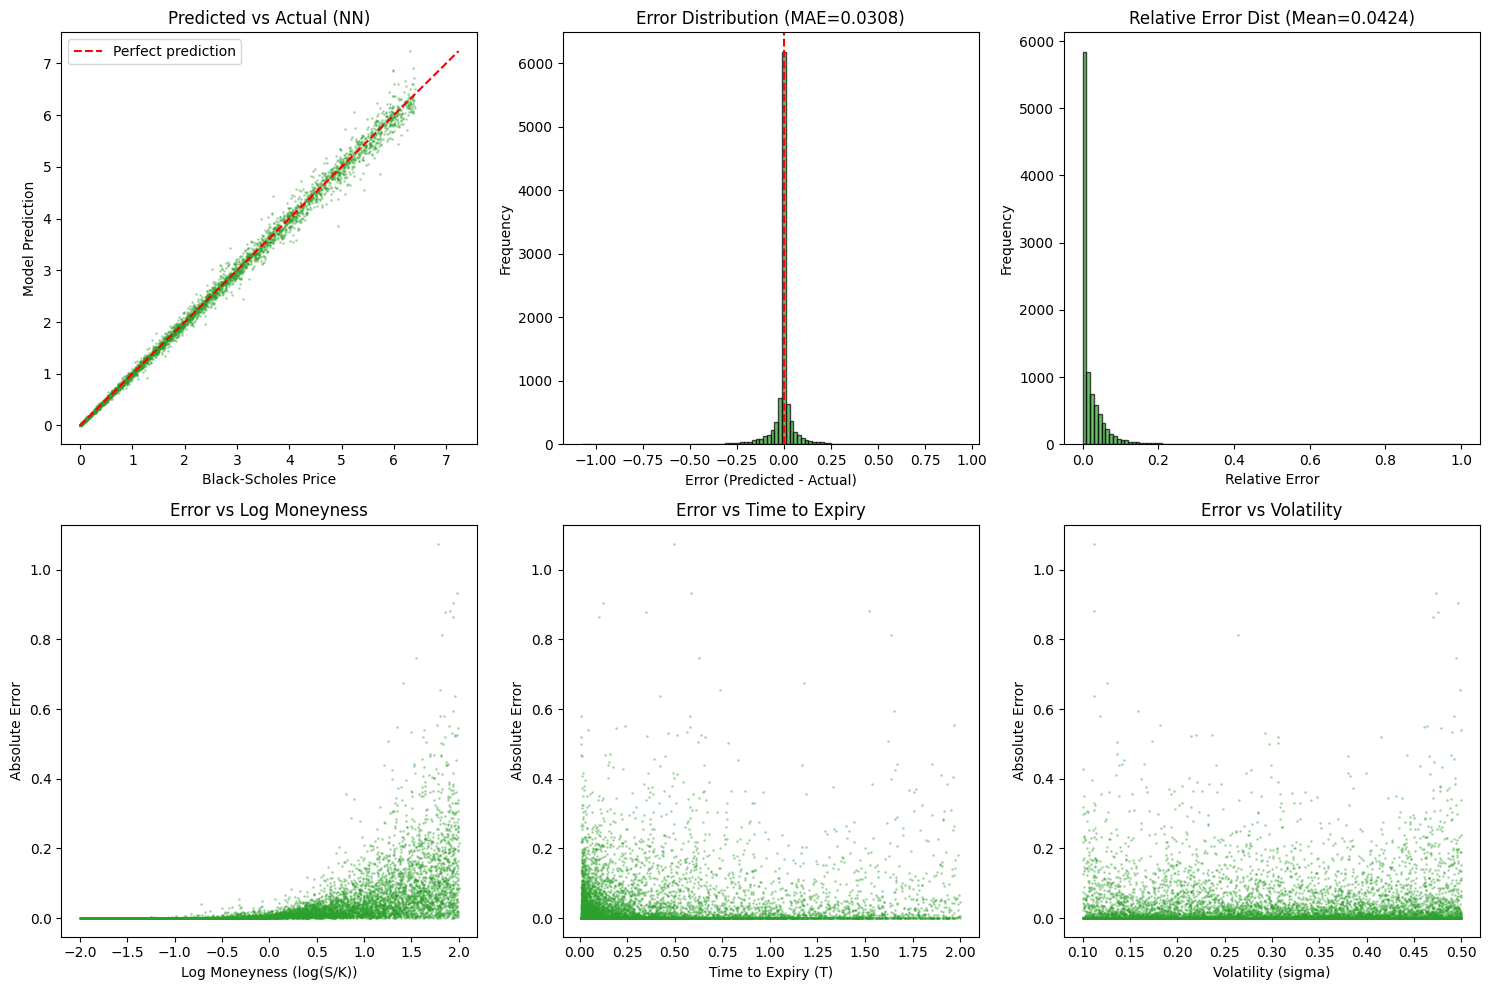

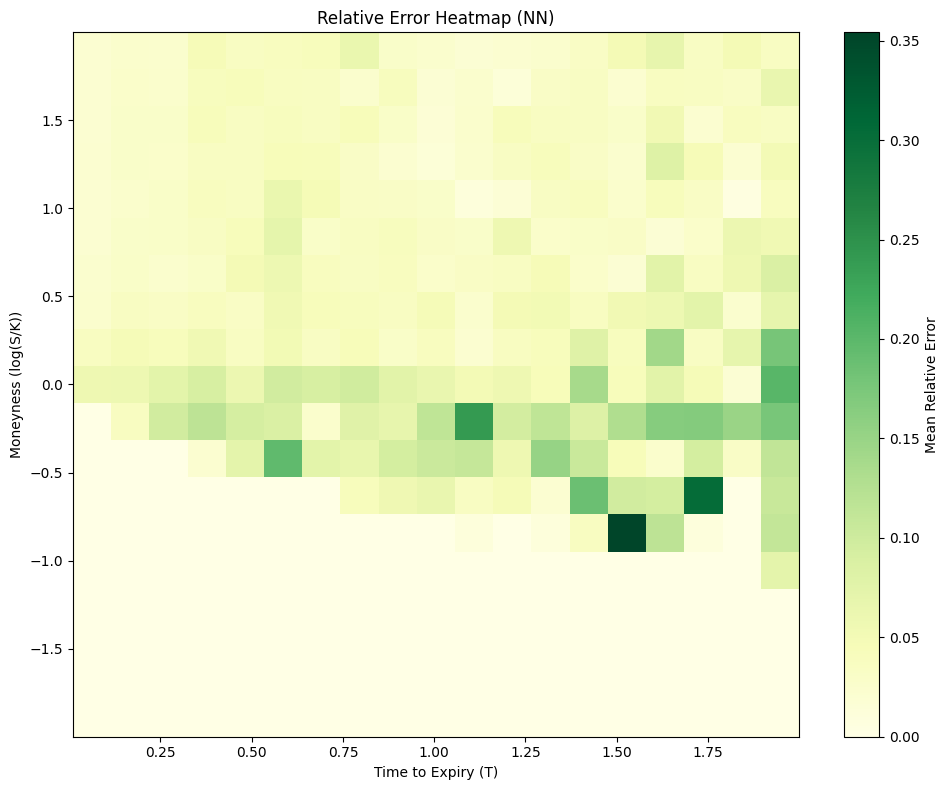


BASELINE (STANDARD FEAT ENGINEERING) MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.030767
Root Mean Square Error (RMSE): 0.075364
Max Absolute Error:            1.075013
--------------------------------------------------
Mean Relative Error:           4.2445%
Median Relative Error:         2.4506%



In [3]:
EVAL_STYLE = {'color': 'tab:green', 'cmap': 'YlGn', 'suffix': '', 'display_name': 'NN'}

_, norm_params = train(
    X_train, y_train, X_val, y_val
)

X_test_raw, y_test = dataset_bundle.test.X, dataset_bundle.test.y_call
X_test, _ = preprocess_test_data(X_test_raw)
y_pred = predict(xgb_model, X_test, norm_params)

def eval(label="Baseline"):
    metrics = compute_metrics(y_test,
                          y_pred,
                          min_value_threshold=0.01)

    plot_validation_results(X_test_raw,
                        y_test,
                        y_pred,
                        metrics,
                        EVAL_STYLE,
                        save_dir=None)

    print_metrics_report(metrics, label)

eval("Baseline (standard feat engineering)")

In [4]:
breadth_model, norm_params = train(
    X_train, y_train, X_val, y_val,
    standardized_data=False
)

[0]	validation_0-rmse:1.57276
[50]	validation_0-rmse:0.20386
[100]	validation_0-rmse:0.03462
[150]	validation_0-rmse:0.01507
[200]	validation_0-rmse:0.01335
[250]	validation_0-rmse:0.01296
[300]	validation_0-rmse:0.01275
[350]	validation_0-rmse:0.01265
[400]	validation_0-rmse:0.01254
[450]	validation_0-rmse:0.01249
[499]	validation_0-rmse:0.01247


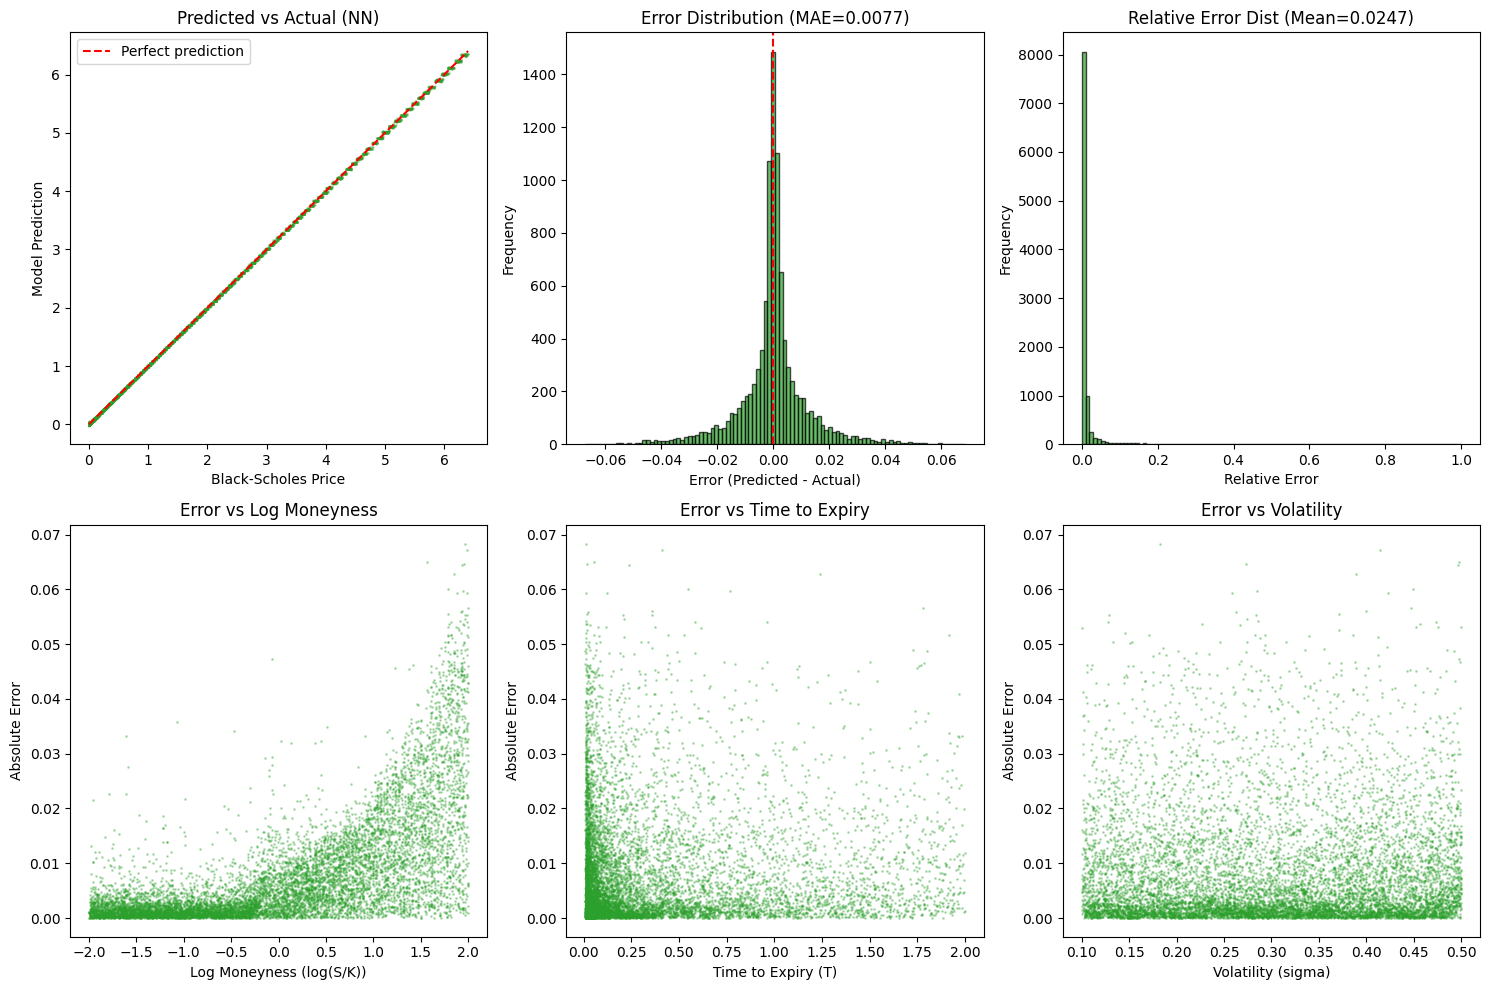

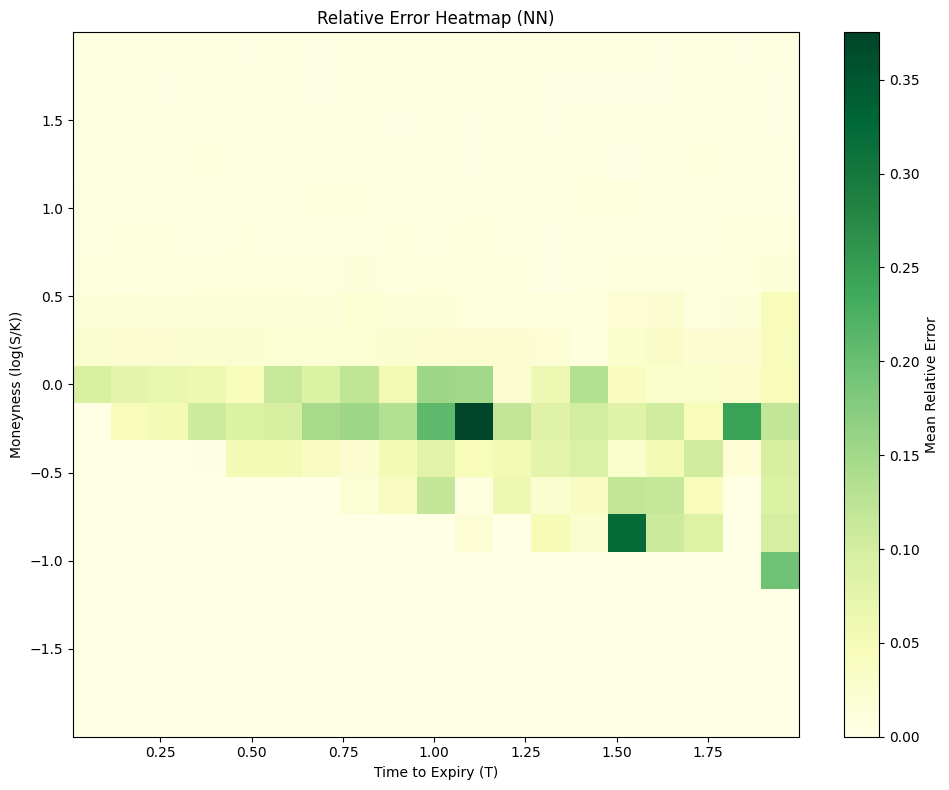


NO STANDARDIZATION MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.007708
Root Mean Square Error (RMSE): 0.012441
Max Absolute Error:            0.068377
--------------------------------------------------
Mean Relative Error:           2.4679%
Median Relative Error:         0.7441%



In [5]:
y_pred = predict(breadth_model, X_test, norm_params)

eval("No standardization")

In [6]:
cfg = cfg.replace(feature_mode="raw")
raw_bundle = generate_bundle(cfg)

X_train, y_train = raw_bundle.train.X, raw_bundle.train.y_call
X_val, y_val = raw_bundle.val.X, raw_bundle.val.y_call

raw_model, norm_params = train(
    X_train, y_train, X_val, y_val
)

[0]	validation_0-rmse:0.95342
[50]	validation_0-rmse:0.21579
[100]	validation_0-rmse:0.13665
[150]	validation_0-rmse:0.12096
[200]	validation_0-rmse:0.11491
[250]	validation_0-rmse:0.11261
[300]	validation_0-rmse:0.11038
[350]	validation_0-rmse:0.10818
[400]	validation_0-rmse:0.10698
[450]	validation_0-rmse:0.10552
[499]	validation_0-rmse:0.10449


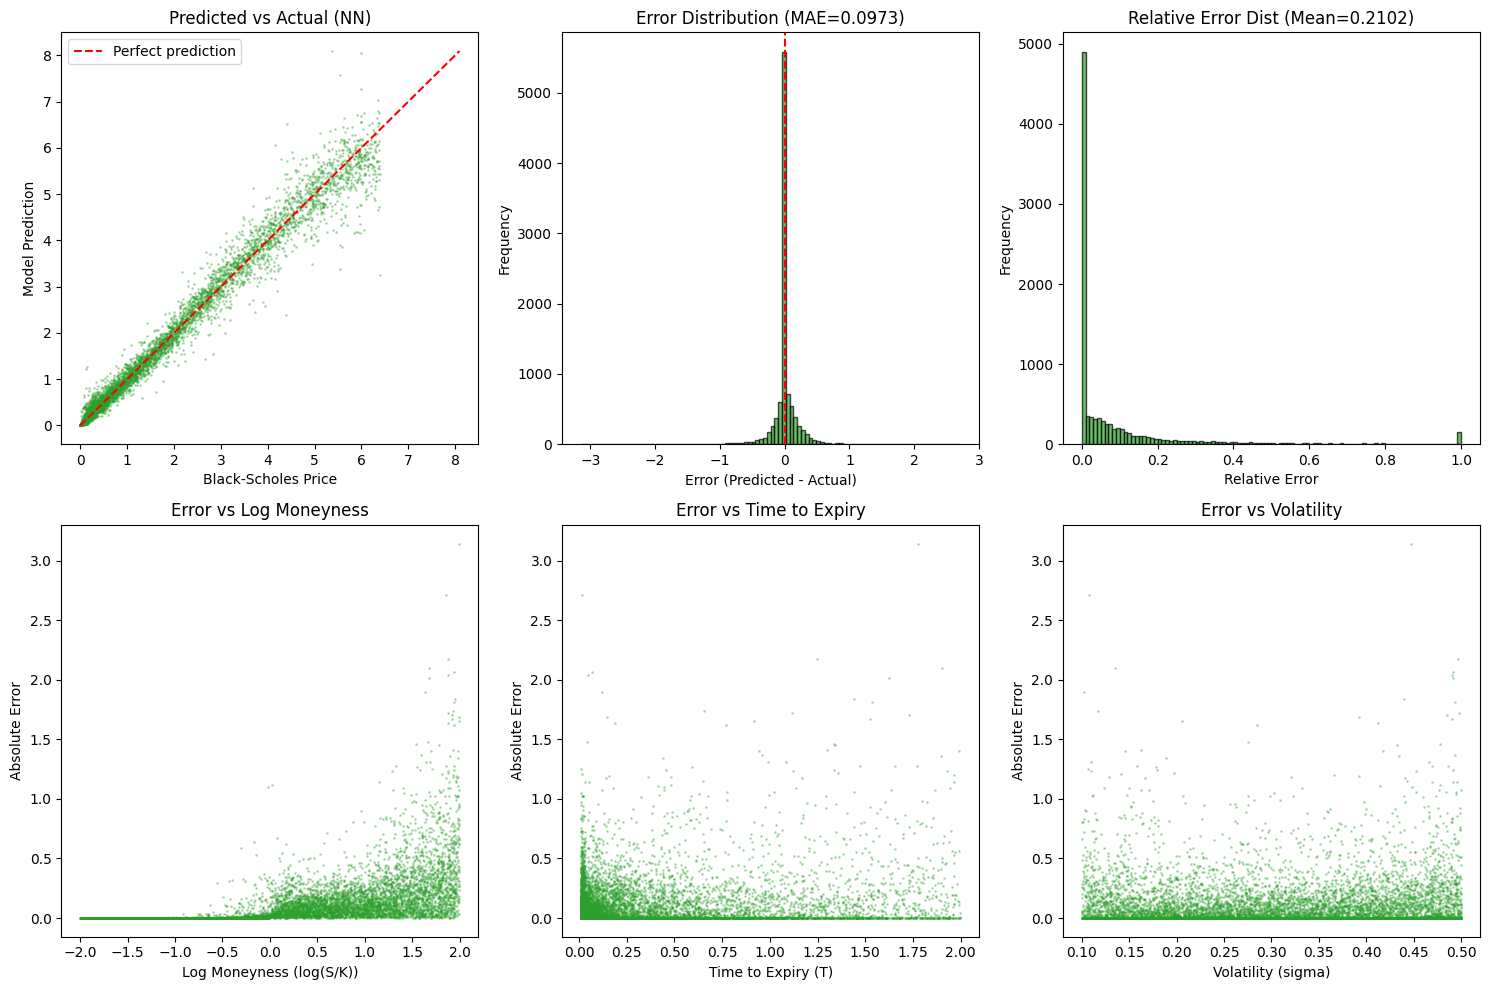

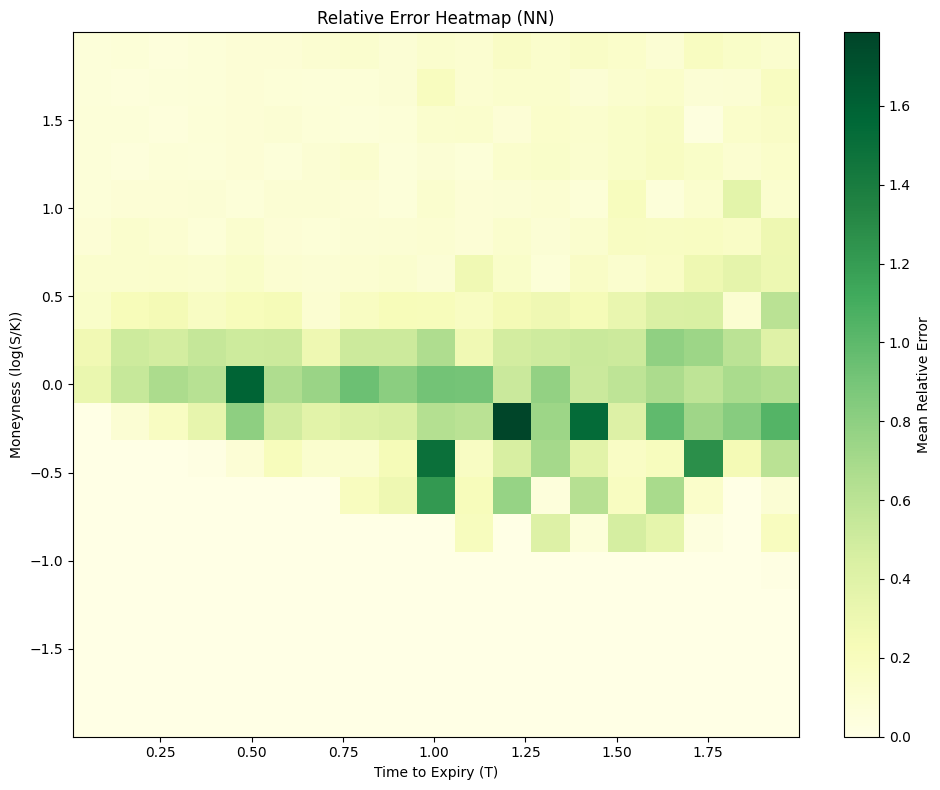


NO FEAT ENGINEERING MODEL VALIDATION REPORT
Mean Absolute Error (MAE):     0.097297
Root Mean Square Error (RMSE): 0.212490
Max Absolute Error:            3.142698
--------------------------------------------------
Mean Relative Error:           21.0224%
Median Relative Error:         9.2095%



In [8]:
y_pred = predict(raw_model, X_test_raw, norm_params)

eval("No feat engineering")

### Conclusions

| Model | MAE | RMSE | Max Error | Mean Rel. Error | Median Rel. Error |
|-------|-----|------|-----------|-----------------|-------------------|
| **XGB Baseline** (all features) | 0.0308 | 0.0754 | 1.075 | 4.24% | 2.45% |
| **XGB No Standardization** | **0.0077** | **0.0124** | **0.068** | **2.47%** | **0.74%** |
| XGB No Feature Engineering (raw S, K) | 0.0973 | 0.2125 | 3.143 | 21.02% | 9.21% |

Non-standardized XGBoost is the best-performing model across all benchmarks in Stage 1, by a wide margin. MAE drops 4x relative to the XGB baseline, and max error drops from 1.08 to 0.07. Note that this also decisively beats the best NN variant, which is the NN on nonstandardized data as well, with MAE 0.0165, max error 0.224 (for more information, refer to `nn_ablation.ipynb`.

Trees split on thresholds, so input standardization is a no-op. The only effect of the log-transform is warping the target into log-space, forcing XGBoost to optimize MSE in a transformed domain. Since C/K is already a well-behaved ratio on a smooth analytic function, this transformation adds distortion without benefit. Removing it lets XGBoost directly minimize the quantity we actually care about.

Yet despite trees being invariant to monotonic input transforms, removing log-moneyness forces the model to learn that only S/K matters (not S and K independently). Trees waste splits discovering this ratio structure, and generalization suffers, at roughly 3x worse MAE than baseline. Hence, on noisy or skewed targets (real IV surfaces), standardization may regain value. But for clean analytic approximation, less preprocessing is more.